# Análisis de caudales diarios (IDEAM)

Análisis exploratorio y control de calidad de series de caudal medio diario con Python y Pandas: comparación de estaciones por departamento, limpieza, ciclo anual y máximos anuales.

**Datos:** IDEAM, portal DHIME (caudal medio diario, m³/s). Nivel de aprobación: *Preliminar*.
**Carpetas:** los CSV descargados van en `datos/<departamento>/` (por ejemplo `datos/tolima/`, `datos/cundinamarca/`, `datos/magdalena/`). Los resultados se guardan en `resultados/`.
**Uso:** edita solo la celda de parámetros y ejecuta todo con *Kernel > Restart & Run All*.

In [1]:
# ========= PARÁMETROS (lo único que normalmente se edita) =========
ESTACION = "BOCATOMA 23017020"   # estación para el análisis detallado (nombre del CSV, sin ".csv")
MAX_HUECO = 4                    # días máximos de hueco que se interpolan
UMBRAL = 95                      # % mínimo de días con dato para que un año sea confiable

# Criterio para que una estación sea apta
MAX_FALTANTES_APTA = 10          # % máximo de datos faltantes tras la limpieza
MIN_ANIOS_APTA = 15              # mínimo de años confiables

# Tramos dudosos que se marcan como vacíos antes de analizar.
# Formato: {"NOMBRE ESTACION": ("2003-02-01", "2004-12-31")}
anomalos = {}

# Nombres derivados (no editar)
corto = ESTACION.rsplit(" ", 1)[0]            # "EL BANCO"
archivo = corto.lower().replace(" ", "_")     # "el_banco"

## 1. Carga de datos

Se leen todos los CSV de la carpeta `datos/`, incluidas sus subcarpetas. **El departamento de cada estación es el nombre de su subcarpeta**; los CSV que estén sueltos en `datos/` quedan como "Sin clasificar". Cada serie se ordena por fecha, se eliminan fechas repetidas y se reindexa a un registro por día, para que los días sin dato queden visibles como vacíos (`NaN`).

In [2]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

carpeta = Path("datos")
Path("resultados").mkdir(exist_ok=True)

if not carpeta.exists():
    raise FileNotFoundError(f"No existe la carpeta 'datos' junto al notebook. Carpeta actual: {Path.cwd()}")
archivos = sorted(carpeta.rglob("*.csv"))
if not archivos:
    raise FileNotFoundError("No hay archivos CSV dentro de la carpeta 'datos'.")
nombres = [a.stem for a in archivos]
if len(nombres) != len(set(nombres)):
    raise ValueError("Hay dos archivos con el mismo nombre en distintas subcarpetas. Renómbralos.")

series, departamento = {}, {}
for ruta in archivos:
    df = pd.read_csv(ruta)
    df["Fecha"] = pd.to_datetime(df["Fecha"])
    s = df.set_index("Fecha")["Valor"].sort_index()
    s = s[~s.index.duplicated()]
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="D"))
    series[ruta.stem] = s
    departamento[ruta.stem] = ruta.parent.name.title() if ruta.parent != carpeta else "Sin clasificar"
    print(f"[{departamento[ruta.stem]}] {ruta.stem} | {s.index.min().date()} -> {s.index.max().date()} | días faltantes: {s.isna().sum()}")

caudales = pd.DataFrame(series)        # una columna por estación

[Cundinamarca] ARRANCAPLUMAS 21237020 | 1998-01-01 -> 2014-12-31 | días faltantes: 58
[Cundinamarca] EL PROFUNDO 21197010 | 1998-01-01 -> 2026-01-01 | días faltantes: 722
[Cundinamarca] PUERTO SALGAR 23037010 | 1998-01-01 -> 2026-01-01 | días faltantes: 105
[Cundinamarca] TOBIA 23067060 | 1998-01-01 -> 2026-01-01 | días faltantes: 282
[Magdalena] CANAL FLORIDA 29067050 | 1998-01-01 -> 2026-01-01 | días faltantes: 2287
[Magdalena] EL BANCO 25027020 | 1998-01-01 -> 2026-01-01 | días faltantes: 410
[Magdalena] GANADERIA CARIBE 29067150 | 1998-01-01 -> 2026-01-01 | días faltantes: 1362
[Magdalena] GUACHACA 15017040 | 1998-01-01 -> 2026-01-01 | días faltantes: 3568
[Magdalena] HACIENDA PUERTO RICO 29067060 | 1998-01-01 -> 2026-01-01 | días faltantes: 8341
[Magdalena] PUENTE FERROCARRIL 29067130 | 1998-01-01 -> 2025-12-06 | días faltantes: 1129
[Tolima] ANCHIQUE 21137040 | 2000-01-01 -> 2020-01-01 | días faltantes: 2166
[Tolima] ANGOSTURA 21137050 | 2000-01-01 -> 2020-01-01 | días faltantes:

## 2. Vista general de las estaciones

Cada estación tiene su propia escala porque sus caudales son muy distintos entre sí. Por eso se grafican por separado.

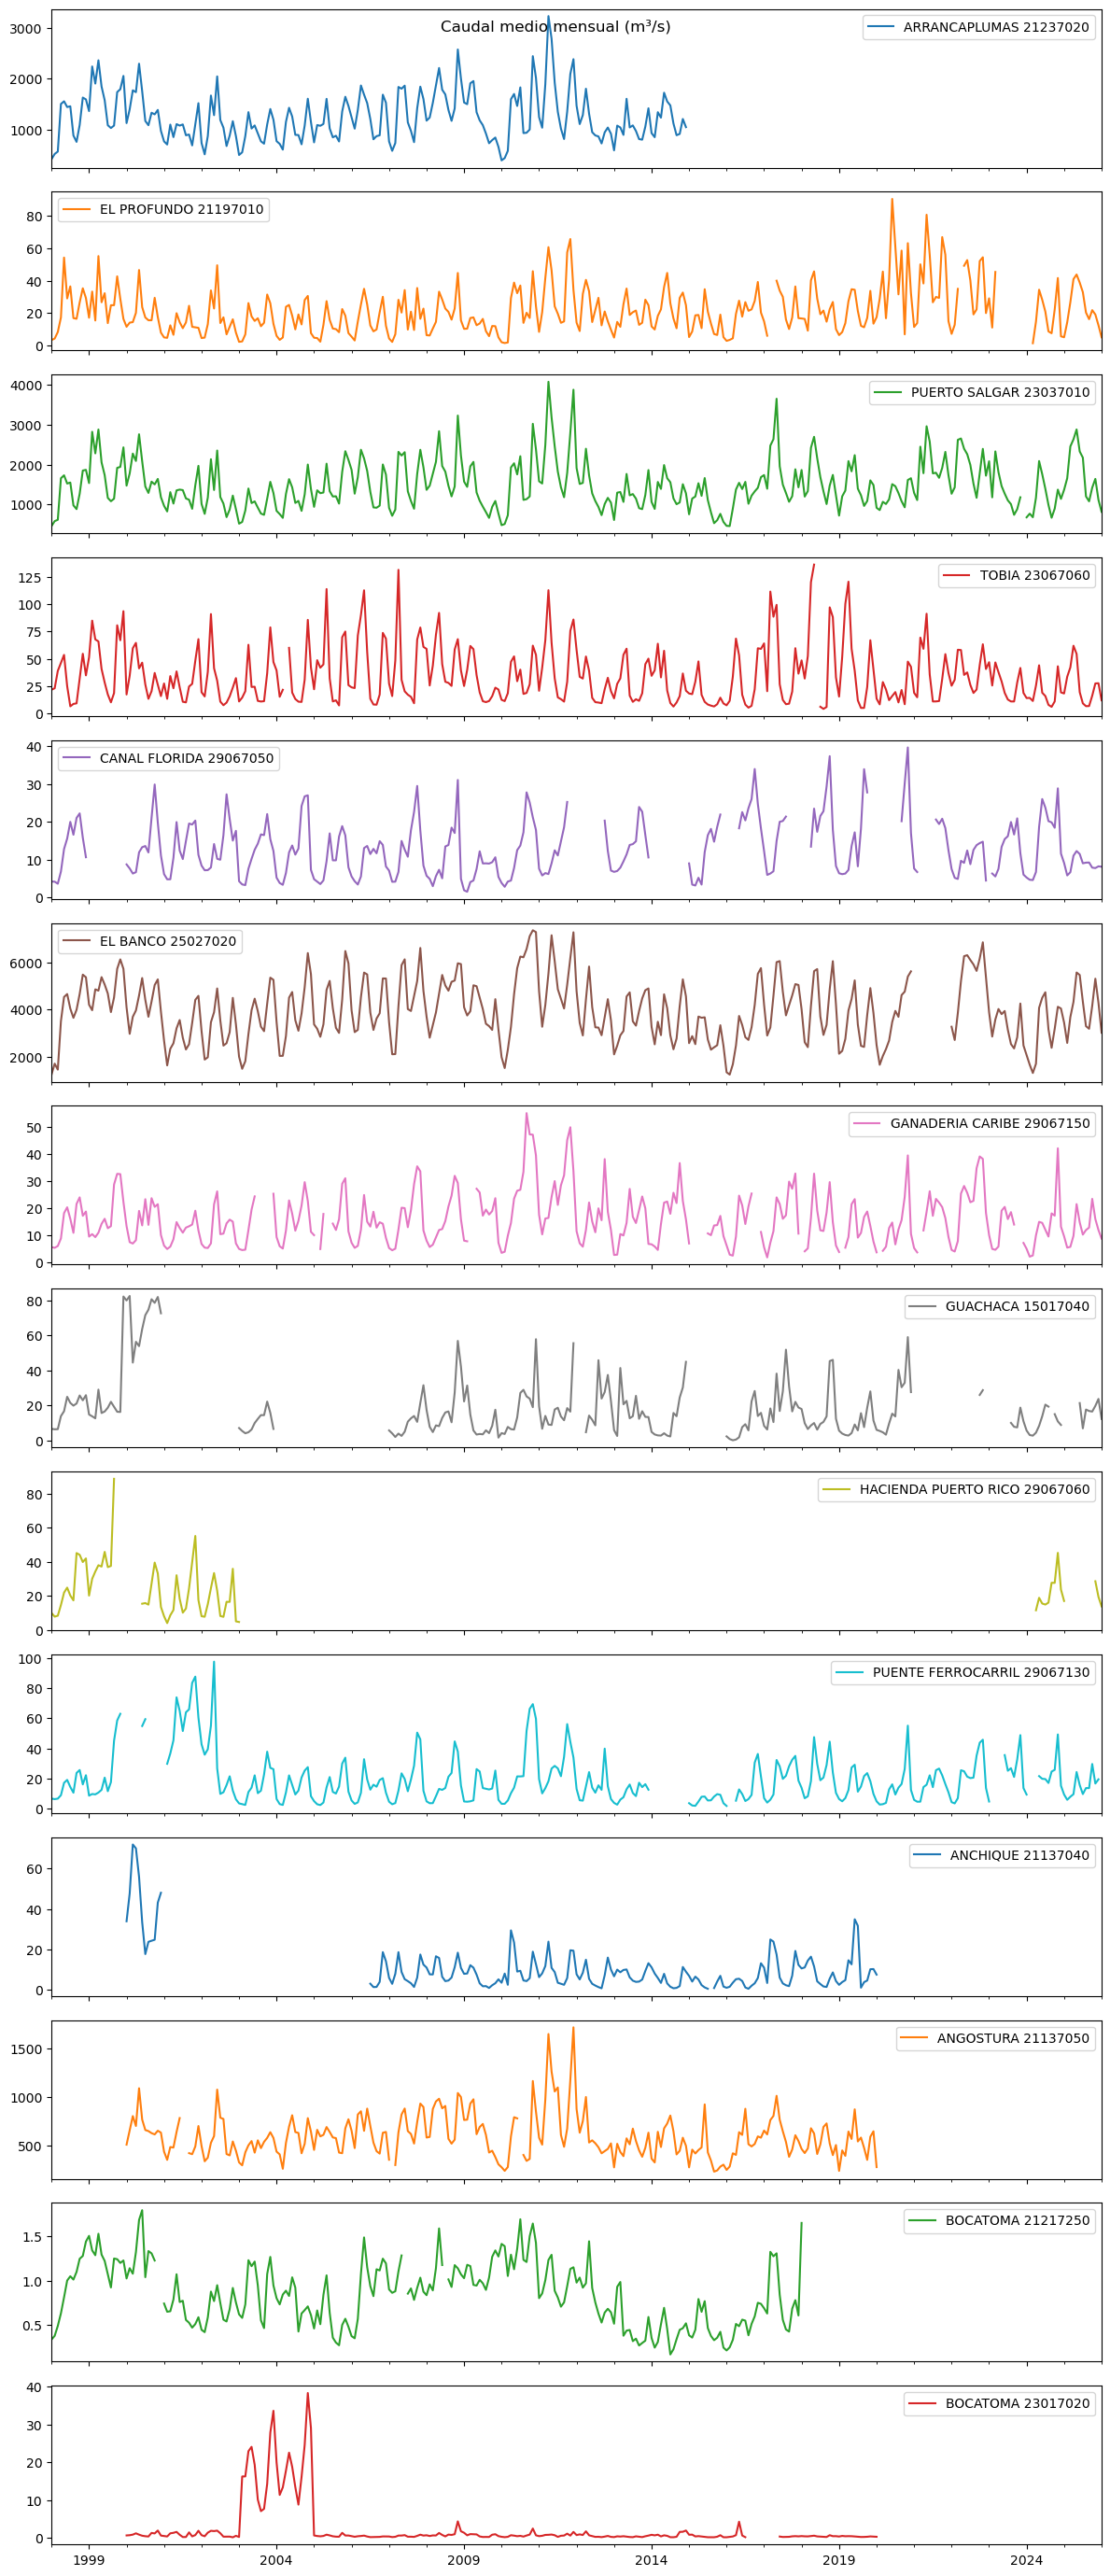

In [3]:
mensual = caudales.resample("MS").mean()
mensual.plot(subplots=True, figsize=(12, 2 * len(caudales.columns)), sharex=True,
             title="Caudal medio mensual (m³/s)")
plt.tight_layout()
plt.show()

## 3. Limpieza y comparación de estaciones

Reglas aplicadas a **todas** las estaciones por igual:

- Cada serie se recorta a su propio rango de registro.
- Solo se interpolan los huecos de `MAX_HUECO` días o menos. Los huecos más largos se dejan vacíos.
- Un año es confiable si tiene al menos `UMBRAL` % de sus días con dato.
- Los tramos listados en `anomalos` se marcan como vacíos antes de analizar.
- Una estación es **apta** si sus faltantes tras la limpieza son menores que `MAX_FALTANTES_APTA` % y tiene al menos `MIN_ANIOS_APTA` años confiables.

                                   inicio         fin  faltantes_antes_%  faltantes_despues_%  años_confiables  años_totales  departamento  caudal_medio_m3s  caudal_max_m3s  hueco_mas_largo_dias   apta
ARRANCAPLUMAS 21237020         1998-01-01  2014-12-31                0.9                  0.8               16            17  Cundinamarca           1244.82          5068.0                    29   True
EL PROFUNDO 21197010           1998-01-01  2026-01-01                7.1                  6.6               19            29  Cundinamarca             21.81           336.5                   362   True
PUERTO SALGAR 23037010         1998-01-01  2026-01-01                1.0                  0.9               27            29  Cundinamarca           1493.88          6595.3                    52   True
TOBIA 23067060                 1998-01-01  2026-01-01                2.8                  2.0               24            29  Cundinamarca             34.53           408.2                    

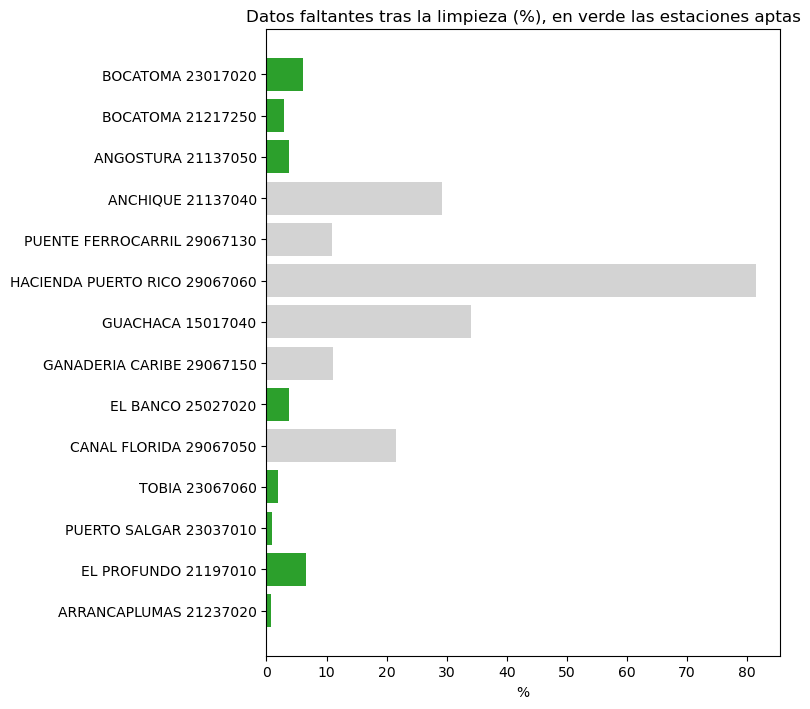

In [4]:
def largo_de_huecos(s):
    """Para cada día: 0 si hay dato, o N si el día pertenece a un hueco de N días seguidos."""
    nan = s.isna()
    bloque = (nan != nan.shift()).cumsum()
    return nan.groupby(bloque).transform("sum")


def analizar_estacion(s, max_hueco=MAX_HUECO, umbral=UMBRAL):
    s = s.loc[s.first_valid_index():s.last_valid_index()]       # rango propio de la estación

    # Rellenar SOLO huecos cortos; los largos quedan vacíos
    nan = s.isna()
    limpio = s.interpolate(method="time", limit_area="inside")
    limpio = limpio.mask(nan & (largo_de_huecos(s) > max_hueco))

    # Máximos anuales y completitud sobre los días reales de cada año
    por_año = limpio.groupby(limpio.index.year)
    anual = pd.DataFrame({"maximo": por_año.max(), "dias_con_dato": por_año.count()})
    anual["dias_del_año"] = [pd.Timestamp(year=y, month=12, day=31).dayofyear for y in anual.index]
    anual["completitud_%"] = (anual["dias_con_dato"] / anual["dias_del_año"] * 100).round(0)

    resumen = {
        "inicio": s.index.min().date(),
        "fin": s.index.max().date(),
        "faltantes_antes_%": round(s.isna().mean() * 100, 1),
        "faltantes_despues_%": round(limpio.isna().mean() * 100, 1),
        "años_confiables": int((anual["completitud_%"] >= umbral).sum()),
        "años_totales": len(anual),
    }
    return limpio, anual, resumen


limpias, anuales, resultados = {}, {}, {}
for nombre in caudales.columns:
    s = caudales[nombre].copy()
    if nombre in anomalos:
        ini, fin = anomalos[nombre]
        s.loc[ini:fin] = float("nan")
    limpias[nombre], anuales[nombre], resultados[nombre] = analizar_estacion(s)

# Tabla comparativa
tabla = pd.DataFrame(resultados).T
for col in ["faltantes_antes_%", "faltantes_despues_%", "años_confiables", "años_totales"]:
    tabla[col] = pd.to_numeric(tabla[col])
tabla["departamento"] = pd.Series(departamento)
tabla["caudal_medio_m3s"] = [round(limpias[n].mean(), 2) for n in tabla.index]
tabla["caudal_max_m3s"] = [round(limpias[n].max(), 1) for n in tabla.index]
tabla["hueco_mas_largo_dias"] = [int(largo_de_huecos(limpias[n]).max()) for n in tabla.index]
tabla["apta"] = (tabla["faltantes_despues_%"] < MAX_FALTANTES_APTA) & (tabla["años_confiables"] >= MIN_ANIOS_APTA)

print(tabla.to_string())
tabla.to_csv("resultados/comparacion_estaciones.csv", encoding="utf-8-sig")

colores = ["tab:green" if a else "lightgray" for a in tabla["apta"]]
plt.figure(figsize=(8, 3 + 0.3 * len(tabla)))
plt.barh(list(tabla.index), tabla["faltantes_despues_%"].values, color=colores)
plt.title("Datos faltantes tras la limpieza (%), en verde las estaciones aptas")
plt.xlabel("%")
plt.tight_layout()
plt.show()

## 4. Mejor estación por departamento

Dentro de cada departamento se toman solo las estaciones aptas y se elige la mejor con este orden de desempate: **menos datos faltantes**, luego **más años confiables** y luego **hueco más corto**. Si un departamento no tiene ninguna estación apta, queda sin estación y se anota.

El caudal medio no se usa como criterio: son ríos distintos y no comparables entre sí. Tampoco hay un puntaje ponderado, porque los pesos serían arbitrarios; un filtro de aptitud con desempate es más transparente y fácil de justificar.

In [5]:
orden = tabla.sort_values(["faltantes_despues_%", "años_confiables", "hueco_mas_largo_dias"],
                          ascending=[True, False, True])
mejores = orden[orden["apta"]].groupby("departamento").head(1).sort_values("departamento")

print("Mejor estación apta por departamento:")
print(mejores[["departamento", "faltantes_despues_%", "años_confiables", "hueco_mas_largo_dias"]].to_string())

sin_apta = sorted(set(tabla["departamento"]) - set(mejores["departamento"]))
if sin_apta:
    print("\nDepartamentos SIN estación apta:", sin_apta)
    print("-> Decide si relajas el criterio para esos departamentos o los dejas fuera, y anótalo.")

# La estación del análisis detallado debe existir y, idealmente, ser la mejor de su departamento
if ESTACION not in limpias:
    raise KeyError(f"ESTACION '{ESTACION}' no está en los datos. Disponibles: {list(limpias)}")
dep = tabla.loc[ESTACION, "departamento"]
mejor_dep = mejores.index[mejores["departamento"] == dep]
if len(mejor_dep) == 0:
    print(f"\nAVISO: {ESTACION} ({dep}) no es apta y {dep} no tiene estación apta.")
elif mejor_dep[0] != ESTACION:
    print(f"\nAVISO: la mejor estación de {dep} es {mejor_dep[0]}, no {ESTACION}.")
else:
    print(f"\n{ESTACION} es la mejor estación apta de {dep}.")

Mejor estación apta por departamento:
                        departamento  faltantes_despues_%  años_confiables  hueco_mas_largo_dias
ARRANCAPLUMAS 21237020  Cundinamarca                  0.8               16                    29
EL BANCO 25027020          Magdalena                  3.7               27                   365
BOCATOMA 21217250             Tolima                  3.0               16                    88

AVISO: la mejor estación de Tolima es BOCATOMA 21217250, no BOCATOMA 23017020.


In [10]:
print(tabla.loc[mejores.index, ["departamento", "inicio", "fin", "años_confiables", "faltantes_despues_%"]])
print("Rango de todas las estaciones:", tabla["inicio"].min(), "->", tabla["fin"].max())

                        departamento      inicio         fin  años_confiables  \
ARRANCAPLUMAS 21237020  Cundinamarca  1998-01-01  2014-12-31               16   
EL BANCO 25027020          Magdalena  1998-01-01  2026-01-01               27   
BOCATOMA 21217250             Tolima  1998-01-01  2018-01-01               16   

                        faltantes_despues_%  
ARRANCAPLUMAS 21237020                  0.8  
EL BANCO 25027020                       3.7  
BOCATOMA 21217250                       3.0  
Rango de todas las estaciones: 1998-01-01 -> 2026-01-01


## 5. Comparación entre las mejores estaciones

Para comparar estaciones entre sí se recortan todas al **periodo común**, de modo que no se comparen años distintos. Como los caudales son de órdenes de magnitud muy diferentes, el ciclo anual se normaliza (caudal de cada mes dividido por el caudal medio de la estación): un valor de 1,2 significa que ese mes el río lleva un 20 % más que su media.

Periodo común: 1998-01-01 -> 2014-12-31


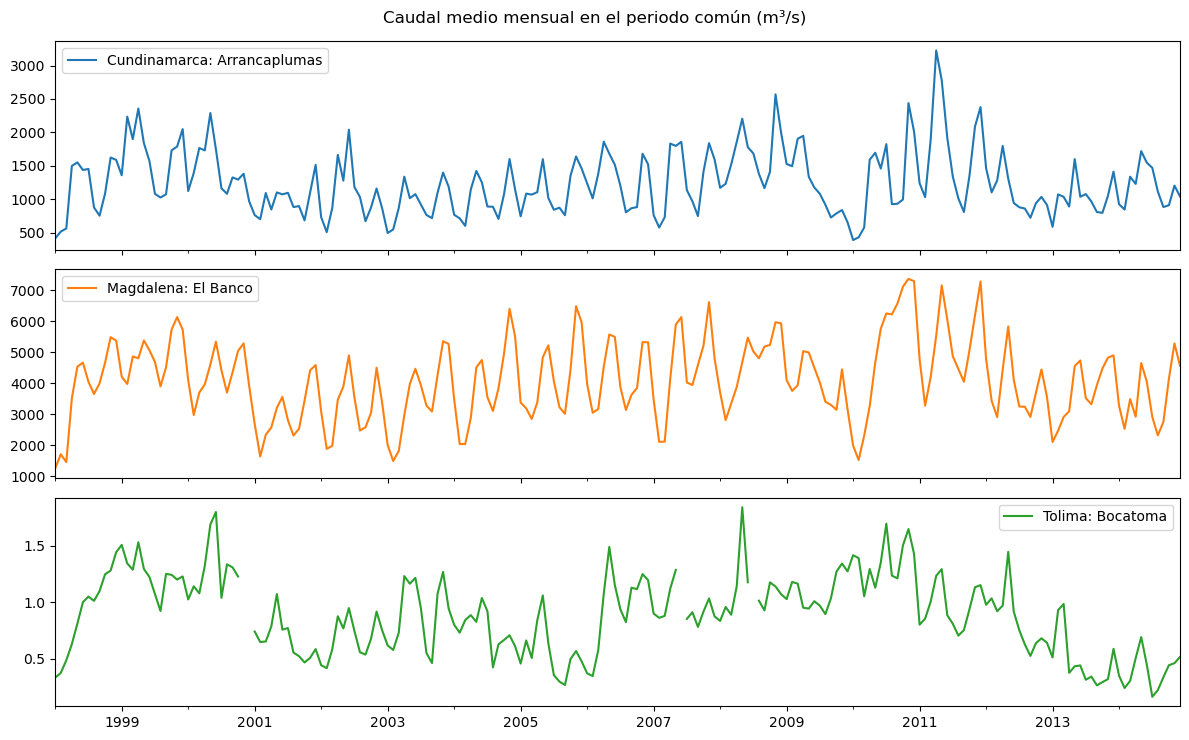

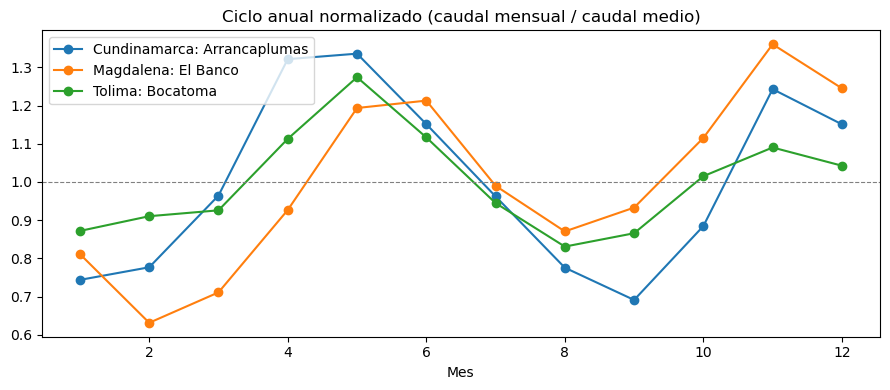

Cundinamarca: Arrancaplumas: pico en el mes 5 (1.34 veces su media) | mínimo en el mes 9 (0.69) | meses sobre la media: [4, 5, 6, 11, 12]
Magdalena: El Banco: pico en el mes 11 (1.36 veces su media) | mínimo en el mes 2 (0.63) | meses sobre la media: [5, 6, 10, 11, 12]
Tolima: Bocatoma: pico en el mes 5 (1.27 veces su media) | mínimo en el mes 8 (0.83) | meses sobre la media: [4, 5, 6, 10, 11, 12]


In [11]:
mejores_est = list(mejores.index)
if len(mejores_est) < 2:
    print("Hace falta al menos dos departamentos con estación apta para comparar.")
else:
    inicio_comun = max(limpias[n].index.min() for n in mejores_est)
    fin_comun = min(limpias[n].index.max() for n in mejores_est)
    if inicio_comun >= fin_comun:
        print("Las mejores estaciones no comparten ningún periodo de registro.")
    else:
        print(f"Periodo común: {inicio_comun.date()} -> {fin_comun.date()}")
        etiquetas = {n: f"{tabla.loc[n, 'departamento']}: {n.rsplit(' ', 1)[0].title()}" for n in mejores_est}
        comun = pd.DataFrame({etiquetas[n]: limpias[n].loc[inicio_comun:fin_comun] for n in mejores_est})

        # Serie mensual de cada una (escalas distintas, por eso en paneles separados)
        comun.resample("MS").mean().plot(subplots=True, figsize=(12, 2.5 * len(mejores_est)),
                                          sharex=True, title="Caudal medio mensual en el periodo común (m³/s)")
        plt.tight_layout()
        plt.savefig("resultados/comparacion_mejores_mensual.png", dpi=150)
        plt.show()

        # Ciclo anual normalizado: comparable entre ríos de distinto tamaño
        ciclo_c = comun.groupby(comun.index.month).mean()
        ciclo_norm = ciclo_c / ciclo_c.mean()
        ax = ciclo_norm.plot(marker="o", figsize=(9, 4), title="Ciclo anual normalizado (caudal mensual / caudal medio)")
        ax.axhline(1, color="gray", lw=0.8, ls="--")
        ax.set_xlabel("Mes")
        plt.tight_layout()
        plt.savefig("resultados/comparacion_mejores_ciclo_normalizado.png", dpi=150)
        plt.show()

for col in ciclo_norm.columns:
    s = ciclo_norm[col]
    print(f"{col}: pico en el mes {int(s.idxmax())} ({s.max():.2f} veces su media) | "
          f"mínimo en el mes {int(s.idxmin())} ({s.min():.2f}) | "
          f"meses sobre la media: {[int(m) for m in s[s > 1].index]}")

## 6. Estación del análisis detallado: ciclo anual y máximos anuales

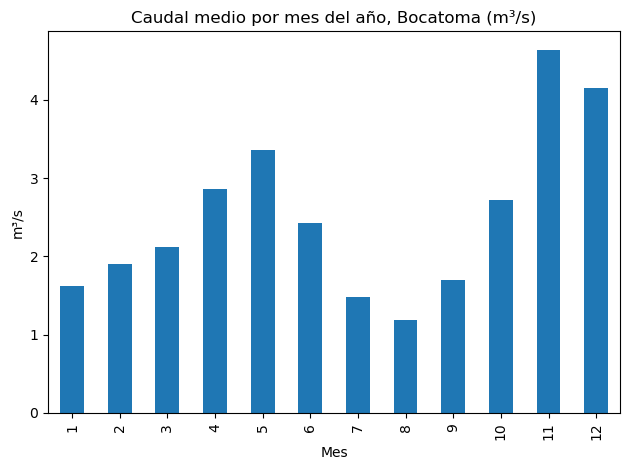

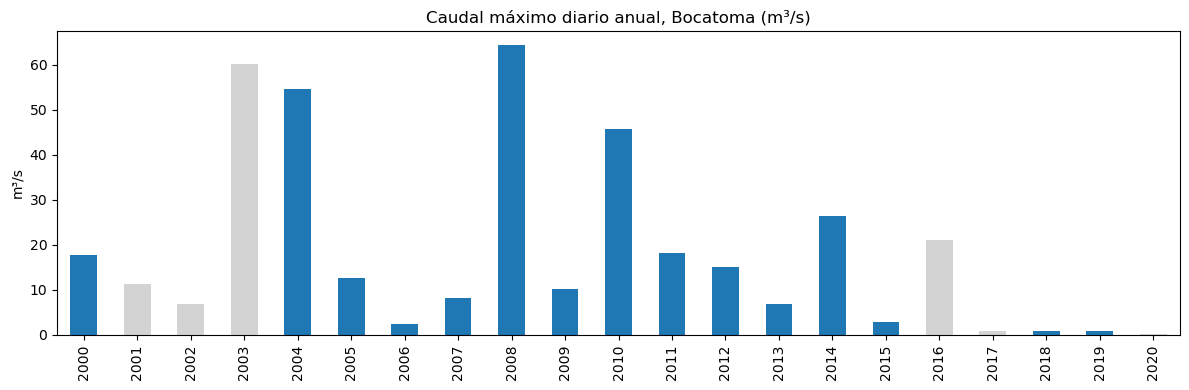

In [7]:
q_limpio, anual = limpias[ESTACION], anuales[ESTACION]

# Ciclo anual: caudal medio por mes del año
ciclo = q_limpio.groupby(q_limpio.index.month).mean()
ax = ciclo.plot(kind="bar", title=f"Caudal medio por mes del año, {corto.title()} (m³/s)")
ax.set_xlabel("Mes")
ax.set_ylabel("m³/s")
plt.tight_layout()
plt.savefig(f"resultados/ciclo_anual_{archivo}.png", dpi=150)
plt.show()

# Máximos anuales: los años excluidos (completitud < UMBRAL) en gris
excluidos = anual[anual["completitud_%"] < UMBRAL].index.tolist()
colores = ["lightgray" if a in excluidos else "tab:blue" for a in anual.index]
ax = anual["maximo"].plot(kind="bar", color=colores, figsize=(12, 4),
                          title=f"Caudal máximo diario anual, {corto.title()} (m³/s)")
ax.set_ylabel("m³/s")
plt.tight_layout()
plt.savefig(f"resultados/maximos_anuales_{archivo}.png", dpi=150)
plt.show()

In [8]:
# ¿Cuándo ocurrió el máximo del registro y cómo luce alrededor?
fecha_max = q_limpio.idxmax()
print("Máximo del registro:", fecha_max.date(), "->", q_limpio.max())
print(q_limpio.loc[fecha_max - pd.Timedelta(days=5): fecha_max + pd.Timedelta(days=5)])

# Años confiables y periodo de retorno empírico (Weibull: T = (n+1)/rango)
confiables = anual[anual["completitud_%"] >= UMBRAL].copy()
print("\nAños excluidos por completitud < %d %%:" % UMBRAL, excluidos)

n = len(confiables)
confiables["rango"] = confiables["maximo"].rank(ascending=False)
confiables["T_años"] = ((n + 1) / confiables["rango"]).round(1)
top = confiables.sort_values("maximo", ascending=False)
print(top[["maximo", "completitud_%", "T_años"]].head(5))

dif = (top["maximo"].iloc[0] - top["maximo"].iloc[1]) / top["maximo"].iloc[0] * 100
print(f"\nEl 1.º y el 2.º máximo difieren solo {dif:.2f} %: el ranking (y su T) es muy sensible a esa diferencia.")

Máximo del registro: 2008-11-26 -> 64.33
2008-11-21     3.694
2008-11-22     1.013
2008-11-23     1.091
2008-11-24     0.966
2008-11-25     1.216
2008-11-26    64.330
2008-11-27     3.400
2008-11-28     1.513
2008-11-29     0.842
2008-11-30     2.566
2008-12-01     1.122
Freq: D, Name: BOCATOMA 23017020, dtype: float64

Años excluidos por completitud < 95 %: [2001, 2002, 2003, 2016, 2017, 2020]
      maximo  completitud_%  T_años
2008   64.33          100.0    16.0
2004   54.59          100.0     8.0
2010   45.80          100.0     5.3
2014   26.44          100.0     4.0
2011   18.24          100.0     3.2

El 1.º y el 2.º máximo difieren solo 15.14 %: el ranking (y su T) es muy sensible a esa diferencia.


## 7. Consultas SQL sobre los mismos datos (SQLite)

Se guardan las series en una base de datos local para practicar SQL con el mismo proyecto.

In [9]:
con = sqlite3.connect("resultados/caudales.db")

# Formato largo (fecha, estación, caudal, departamento) y carga en SQLite
largo = (caudales.rename_axis(index="fecha", columns="estacion")
                 .stack().rename("caudal").dropna().reset_index())
largo["departamento"] = largo["estacion"].map(departamento)
largo.to_sql("caudales_diarios", con, if_exists="replace", index=False)

por_depto = """
    SELECT departamento,
           COUNT(DISTINCT estacion) AS estaciones,
           COUNT(*) AS dias_con_dato
    FROM caudales_diarios
    GROUP BY departamento
    ORDER BY departamento
"""
print(pd.read_sql(por_depto, con).to_string(index=False))

resumen_sql = """
    SELECT estacion,
           DATE(MIN(fecha)) AS inicio,
           DATE(MAX(fecha)) AS fin,
           COUNT(*) AS dias_con_dato,
           ROUND(AVG(caudal), 1) AS caudal_medio
    FROM caudales_diarios
    GROUP BY estacion
    ORDER BY estacion
"""
print("\nResumen por estación:")
print(pd.read_sql(resumen_sql, con).to_string(index=False))

huecos_sql = """
    SELECT estacion,
           strftime('%Y', fecha) AS año,
           COUNT(*) AS dias_con_dato
    FROM caudales_diarios
    GROUP BY estacion, año
    HAVING dias_con_dato < 330
    ORDER BY estacion, año
"""
print("\nAños con menos de 330 días con dato:")
print(pd.read_sql(huecos_sql, con).to_string(index=False))
con.close()

departamento  estaciones  dias_con_dato
Cundinamarca           4          35726
   Magdalena           6          44245
      Tolima           4          26061

Resumen por estación:
                     estacion     inicio        fin  dias_con_dato  caudal_medio
            ANCHIQUE 21137040 2000-01-01 2020-01-01           5140          10.1
           ANGOSTURA 21137050 2000-01-01 2020-01-01           7017         605.4
       ARRANCAPLUMAS 21237020 1998-01-01 2014-12-31           6151        1244.8
            BOCATOMA 21217250 1998-01-01 2018-01-01           7077           0.8
            BOCATOMA 23017020 2000-01-01 2020-01-01           6827           2.5
       CANAL FLORIDA 29067050 1998-01-01 2026-01-01           7941          12.9
            EL BANCO 25027020 1998-01-01 2026-01-01           9818        3983.7
         EL PROFUNDO 21197010 1998-01-01 2026-01-01           9506          21.8
    GANADERIA CARIBE 29067150 1998-01-01 2026-01-01           8866          16.2
       

## 8. Limitaciones

- Los datos son **preliminares** (no validados por el IDEAM) y cubren el periodo descargado (ver tabla de la sección 3).
- La mejor estación de un departamento es la de **mejor calidad de datos**, no necesariamente la más representativa: un río puede cruzar varios departamentos, y un estudio real elige la estación por cuenca y por el objetivo (crecientes, caudales mínimos).
- Las comparaciones entre estaciones se hacen en el **periodo común**, que puede ser corto si alguna estación tiene un registro reciente.
- El periodo de retorno de Weibull es una referencia empírica y **no sirve para diseño**. Un estudio real usaría distribuciones de frecuencia (Gumbel, Log-Pearson III) con series más largas.
- Los máximos de los años con huecos pueden estar subestimados. Los años con menos del 90 % de datos se excluyeron.
- La interpolación en huecos cortos supone variación suave del caudal, lo que puede no cumplirse durante una creciente.
- Posible cambio en la forma de registro del dato: los valores antiguos son enteros y algunos recientes tienen decimales. Es una observación sin verificar.
- Los tramos con valores sospechosos, si los hay, se declaran en el diccionario `anomalos` y su causa no está confirmada.